___
<a href='https://honglab.ai'><p style="text-align:center;"><img src='https://lh3.googleusercontent.com/lY3ySXooSmwsq5r-mRi7uiypbo0Vez6pmNoQxMFhl9fmZJkRHu5lO2vo7se_0YOzgmDyJif9fi4_z0o3ZFdwd8NVSWG6Ea80uWaf3pOHpR4GHGDV7kaFeuHR3yAjIJjDgfXMxsvw=w2400'  class="center" width="50%" height="50%"/></p></a>
___
<center><em>Content Copyright by HongLab, Inc.</em></center>

# 작은 GPT 만들기

**해당 강의:** 파트3 챕터6 「파이토치 구현」

강의에서 본 부품(RMSNorm, RoPE, 어텐션, SwiGLU, 블록)을 칸 하나에 하나씩 만들어 GPT를 조립합니다.
CPU로 몇 분 훈련해 손실이 내려가는 것을 본 다음, 같은 크기의 모델을 GPU로 끝까지 훈련한 실습 자료의 체크포인트를 불러와 동화를 생성합니다.
마지막으로 이 모델에서 어텐션 가중치를 꺼내, 「트랜스포머의 구조」 강의에서 본 어텐션 행렬을 직접 확인합니다.

- 실행 시간: 2분 안팎 (CPU, 대부분 훈련)
- 설치할 것: torch, matplotlib, regex
- 준비: 실습 자료의 `exp02_tinystories_Korean` 폴더 (토크나이저, `valid.txt`, `tiny_1ep.pt` 체크포인트를 씁니다)

In [1]:
import matplotlib.pyplot as plt
from matplotlib import font_manager

# 그래프에 한글이 보이도록 설치된 한글 폰트를 찾아 씁니다 (윈도우·맥·리눅스 순)
installed = {f.name for f in font_manager.fontManager.ttflist}
for name in ["Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans CJK KR"]:
    if name in installed:
        plt.rcParams["font.family"] = name
        break
plt.rcParams["axes.unicode_minus"] = False

from pathlib import Path

# 「실습 자료 다운로드」 레슨에서 받은 실습 자료 중 exp02_tinystories_Korean 폴더의 위치입니다.
# 이 노트북 폴더 안에 옮겨 두었다면 그대로 두고, 다른 곳에 있다면 경로를 고치세요.
EXP02 = Path("exp02_tinystories_Korean")
assert (EXP02 / "tokenizer").exists(), f"{EXP02.resolve()}가 없습니다. 실습 자료의 exp02_tinystories_Korean 폴더 경로를 확인하세요."

import math
import sys
import time
from dataclasses import dataclass

import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0)

# 실습 자료의 src 폴더를 경로에 넣습니다. 토크나이저(bpe.py)를 가져다 쓰고,
# 체크포인트 안에 함께 저장된 설정(src/model.py의 GPTConfig)도 이 경로에서 찾아 읽습니다.
sys.path.insert(0, str(EXP02 / "src"))
from bpe import BPETokenizer

## 토크나이저와 데이터

앞 노트북에서 본 어휘 8천 개짜리 토크나이저를 씁니다. 이야기 사이에는 끝 표시 `<|endoftext|>`가 들어 있습니다.

훈련 데이터로는 실습 자료의 검증용 동화(`valid.txt`, 약 1,400만 자)를 씁니다.
앞 200만 자는 훈련에, 그다음 20만 자는 검증에 씁니다. 실험의 실제 훈련 데이터는 따로 내려받아야 하고 훨씬 큽니다(6억 토큰).

In [2]:
tok = BPETokenizer.load(EXP02 / "tokenizer" / "ko_tinystories_bpe_8k.json")
EOT = tok.special_ids["<|endoftext|>"]

text = (EXP02 / "dataset" / "ko_tinystories" / "valid.txt").read_text(encoding="utf-8")
print(f"전체 {len(text):,}자\n")
print(text[:300])

t0 = time.time()
train_data = torch.tensor(tok.encode(text[:2_000_000]))
val_data = torch.tensor(tok.encode(text[2_000_000:2_200_000]))
print(f"\n훈련 토큰 {len(train_data):,}개 · 검증 토큰 {len(val_data):,}개 (토큰화 {time.time() - t0:.0f}초)")

전체 14,090,873자

다람쥐는 장미꽃을 좋아했습니다.  예쁜 장미꽃을 보며 행복해했습니다.  다람쥐는 꽃잎을 따먹고 싶어했지만 장미꽃은 다른 동물들에게도 중요했습니다. 거북이는 장미꽃 옆에서 국수를 먹고 있었습니다.  다람쥐가 장미꽃을 따먹으려고 했어요.  거북이는 다람쥐에게 말했습니다.  "장미꽃은 소중해.  다른 사람들도 좋아해." 다람쥐는 거북이 말을 들었습니다.  다람쥐는 장미꽃을 따먹지 않았어요.  다람쥐는 장미꽃과 함께 국수를 먹었습니다. 다람쥐는 다른 친구들과 장미꽃을 함께 보며 기뻤습니다.
<|endoftext|>
흐린 날씨에 고양이는 강



훈련 토큰 659,058개 · 검증 토큰 65,923개 (토큰화 1초)


## 설정 — GPTConfig

모델 크기를 정하는 숫자들을 한 클래스에 모읍니다. 강의 예시는 벡터 512·8층·8헤드(약 3천만 파라미터)였습니다.
여기서는 실습 자료의 가장 작은 모델(tiny)과 같은 크기로 만듭니다. 그래야 뒤에서 그 체크포인트를 그대로 불러올 수 있습니다.

In [3]:
@dataclass
class GPTConfig:
    vocab_size: int = 8000
    d_model: int = 256        # 토큰 하나를 나타내는 벡터 크기
    n_layer: int = 4          # 트랜스포머 블록 수
    n_head: int = 4           # 어텐션 헤드 수
    d_ff: int = 704           # SwiGLU 안에서 넓히는 폭 (약 8/3 × d_model)
    max_seq_len: int = 1024   # 한 번에 받는 최대 토큰 수
    rope_theta: float = 10000.0
    tie_embeddings: bool = True

    @property
    def head_dim(self):
        return self.d_model // self.n_head

cfg = GPTConfig()
print(cfg, "head_dim =", cfg.head_dim)

GPTConfig(vocab_size=8000, d_model=256, n_layer=4, n_head=4, d_ff=704, max_seq_len=1024, rope_theta=10000.0, tie_embeddings=True) head_dim = 64


## RMSNorm — 크기만 1로

벡터의 크기(제곱 평균의 제곱근, RMS)로 나눠 크기를 1로 맞추고, 차원마다 학습되는 배율 γ를 곱합니다.
강의 화면에서는 γ를 `g`라고 썼는데, 여기서는 체크포인트와 이름을 맞추려고 `weight`라고 씁니다.

In [4]:
class RMSNorm(nn.Module):
    def __init__(self, d, eps=1e-5):
        super().__init__()
        self.weight = nn.Parameter(torch.ones(d))   # γ
        self.eps = eps

    def forward(self, x):
        return x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps) * self.weight

x = torch.randn(3, 256) * 5
y = RMSNorm(256)(x)
print("RMS 전:", x.pow(2).mean(-1).sqrt())
print("RMS 후:", y.pow(2).mean(-1).sqrt())
print("방향은 그대로(코사인 유사도):", F.cosine_similarity(x, y, dim=-1))

RMS 전: tensor([4.6962, 5.4455, 5.2609])
RMS 후: tensor([1.0000, 1.0000, 1.0000], grad_fn=<SqrtBackward0>)
방향은 그대로(코사인 유사도): tensor([1., 1., 1.], grad_fn=<SumBackward1>)


## RoPE — 위치만큼 돌린다

위치마다 돌릴 각도를 미리 계산해 표(cos, sin)로 만들어 두고, Q와 K에만 적용합니다. V는 돌리지 않습니다.

In [5]:
def rope_tables(head_dim, max_seq_len, theta):
    inv_freq = 1.0 / (theta ** (torch.arange(0, head_dim, 2).float() / head_dim))
    angles = torch.outer(torch.arange(max_seq_len).float(), inv_freq)   # (T, head_dim/2)
    emb = torch.cat((angles, angles), dim=-1)                           # (T, head_dim)
    return emb.cos()[None, None], emb.sin()[None, None]                 # (1, 1, T, head_dim)

def rotate_half(x):
    x1, x2 = x.chunk(2, dim=-1)
    return torch.cat((-x2, x1), dim=-1)

def apply_rope(q, k, cos, sin):
    return q * cos + rotate_half(q) * sin, k * cos + rotate_half(k) * sin

## 어텐션

강의의 네 단계 그대로입니다. ① Q·K·V를 한 번에 만들어 헤드로 나누고, ② RoPE를 적용하고, ③ 인과 마스크를 만들고, ④ 점수를 매겨 V를 섞습니다.

실습 자료의 코드는 ③④를 `F.scaled_dot_product_attention` 한 줄로 처리합니다(결과는 같고 더 빠릅니다).
여기서는 뒤에서 어텐션 가중치를 꺼내 보려고 직접 계산하고, `keep_attn`이 켜져 있으면 가중치를 저장해 둡니다.
강의 화면에 있던 QK-norm은 이 모델에 없습니다. 실습 자료의 모델이 QK-norm 없이 훈련됐기 때문입니다.

In [6]:
class Attention(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.n_head, self.head_dim = cfg.n_head, cfg.head_dim
        self.wqkv = nn.Linear(cfg.d_model, 3 * cfg.d_model, bias=False)
        self.wo = nn.Linear(cfg.d_model, cfg.d_model, bias=False)
        self.keep_attn = False
        self.attn = None

    def forward(self, x, cos, sin):
        B, T, C = x.shape
        q, k, v = self.wqkv(x).split(C, dim=-1)                              # ① (B, T, C) 셋
        q, k, v = (t.view(B, T, self.n_head, self.head_dim).transpose(1, 2)  #   (B, H, T, hd)
                   for t in (q, k, v))
        q, k = apply_rope(q, k, cos, sin)                                    # ② 위치만큼 회전
        mask = torch.triu(torch.full((T, T), float("-inf")), diagonal=1)     # ③ 미래는 −∞
        att = q @ k.transpose(-2, -1) / math.sqrt(self.head_dim)             # ④ 점수
        att = (att + mask).softmax(dim=-1)                                   #   가로줄 합 1
        if self.keep_attn:
            self.attn = att.detach()
        y = (att @ v).transpose(1, 2).reshape(B, T, C)                       #   V 섞고 헤드 이어 붙이기
        return self.wo(y)

## SwiGLU — 넓혔다 좁히며 곱한다

두 갈래로 넓혀서, SiLU를 거친 게이트 갈래가 다른 갈래를 얼마나 통과시킬지 정합니다. 마지막 행렬이 다시 좁힙니다.

In [7]:
class SwiGLU(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.w_gate = nn.Linear(cfg.d_model, cfg.d_ff, bias=False)
        self.w_up = nn.Linear(cfg.d_model, cfg.d_ff, bias=False)
        self.w_down = nn.Linear(cfg.d_ff, cfg.d_model, bias=False)

    def forward(self, x):
        return self.w_down(F.silu(self.w_gate(x)) * self.w_up(x))

## 블록 — 정규화하고 더하기

RMSNorm → 어텐션 → 잔차 더하기, RMSNorm → SwiGLU → 잔차 더하기입니다.

In [8]:
class Block(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.attn_norm = RMSNorm(cfg.d_model)
        self.attn = Attention(cfg)
        self.ffn_norm = RMSNorm(cfg.d_model)
        self.ffn = SwiGLU(cfg)

    def forward(self, x, cos, sin):
        x = x + self.attn(self.attn_norm(x), cos, sin)
        x = x + self.ffn(self.ffn_norm(x))
        return x

## GPT — 네 부품의 조립

임베딩 → 블록 N개 → 최종 RMSNorm → 언어모델 헤드입니다. 헤드는 새 표를 만들지 않고 임베딩 표를 같이 씁니다(가중치 공유).
가중치는 0.02 정도의 작은 난수로 초기화합니다. 잔차로 더해지는 출력 행렬(`wo`, `w_down`)은 층이 깊을수록 더 작게 시작합니다(GPT-2 방식).

In [9]:
class GPT(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg
        self.token_emb = nn.Embedding(cfg.vocab_size, cfg.d_model)
        self.blocks = nn.ModuleList([Block(cfg) for _ in range(cfg.n_layer)])
        self.final_norm = RMSNorm(cfg.d_model)
        self.lm_head = nn.Linear(cfg.d_model, cfg.vocab_size, bias=False)
        if cfg.tie_embeddings:
            self.lm_head.weight = self.token_emb.weight            # 가중치 공유

        cos, sin = rope_tables(cfg.head_dim, cfg.max_seq_len, cfg.rope_theta)
        self.register_buffer("rope_cos", cos, persistent=False)
        self.register_buffer("rope_sin", sin, persistent=False)

        for m in self.modules():                                   # 초기화
            if isinstance(m, (nn.Linear, nn.Embedding)):
                nn.init.normal_(m.weight, mean=0.0, std=0.02)
        for name, p in self.named_parameters():
            if name.endswith("wo.weight") or name.endswith("w_down.weight"):
                nn.init.normal_(p, mean=0.0, std=0.02 / math.sqrt(2 * cfg.n_layer))

    def forward(self, idx):
        T = idx.shape[1]
        x = self.token_emb(idx)                                    # (B, T) → (B, T, C)
        cos, sin = self.rope_cos[:, :, :T], self.rope_sin[:, :, :T]
        for blk in self.blocks:
            x = blk(x, cos, sin)                                   # 모양 그대로 (B, T, C)
        return self.lm_head(self.final_norm(x))                    # (B, T, vocab)

model = GPT(cfg)
print(f"파라미터 {sum(p.numel() for p in model.parameters()):,}개")

idx = train_data[:16].view(2, 8)                                   # 문장 2개 × 토큰 8개
logits = model(idx)
print("입력", tuple(idx.shape), "→ 출력", tuple(logits.shape))

파라미터 5,261,568개
입력 (2, 8) → 출력 (2, 8, 8000)


출력은 위치마다 어휘 8천 개에 매긴 점수(logits)입니다.

아직 훈련하지 않은 모델은 모든 토큰을 거의 같은 확률로 고릅니다. 그때의 손실은 ln(8000) ≈ 8.99 근처입니다.

In [10]:
y = train_data[1:17].view(2, 8)                                    # 한 칸 민 정답
loss = F.cross_entropy(logits.view(-1, cfg.vocab_size), y.view(-1))
print(f"훈련 전 손실 {loss.item():.2f} (ln 8000 = {math.log(8000):.2f})")

훈련 전 손실 9.07 (ln 8000 = 8.99)


## 생성 — 고르고 다시 넣기

지금까지 나온 토큰을 모델에 넣고, 마지막 위치의 점수를 softmax로 확률로 바꿔 토큰 하나를 뽑아 뒤에 붙입니다. 이것을 반복합니다(자기회귀).
여기서는 확률이 높은 50개 안에서만 뽑습니다(top-k). 끝 표시 `<|endoftext|>`가 나오면 멈춥니다.

In [11]:
@torch.no_grad()
def generate(model, prompt, max_new=150, temperature=1.0, top_k=50, seed=0):
    torch.manual_seed(seed)
    model.eval()
    idx = torch.tensor([tok.encode(prompt)])
    for _ in range(max_new):
        logits = model(idx[:, -model.cfg.max_seq_len:])[:, -1] / temperature   # 마지막 위치의 점수
        v, _ = torch.topk(logits, top_k)
        logits[logits < v[:, [-1]]] = float("-inf")                          # 상위 k개만 남김
        nxt = torch.multinomial(logits.softmax(-1), 1)
        if nxt.item() == EOT:
            break
        idx = torch.cat([idx, nxt], dim=1)
    model.train()
    return tok.decode(idx[0].tolist())

print(generate(model, "옛날 옛날에,", max_new=40))

옛날 옛날에, 윙윙 도망쳤다 도망쳤다 보물 모두 모두 들어 모두는 모두 모두 맡 거세졌다 숨은 숨은무서워무서워 희수에게 낼왜 가지가조 중요해 희주�� 울상을 행복해졌다 모두에게 탔습니다 괜히 괜히 붙OOO자를 잔디밭에 내다 숙였다 옆을앞


훈련하지 않았으니 아무 토큰이나 이어 붙입니다.

## 훈련 루프

데이터에서 무작위 위치 B곳을 골라 길이 T만큼 잘라 입력 x로 쓰고, 한 칸 민 것을 정답 y로 씁니다.
한 스텝은 강의의 여섯 단계입니다. 학습률 정하기 → 순전파와 손실 → 역전파 → 그래디언트 클리핑 → 업데이트 → 기울기 비우기.
학습률은 웜업으로 올렸다가 코사인 곡선으로 내립니다. 일정 스텝마다 검증 데이터로 손실을 잽니다.

In [12]:
B, T = 16, 128
STEPS, WARMUP, LR = 300, 30, 2e-3

def get_batch(data):
    ix = torch.randint(len(data) - T - 1, (B,))
    x = torch.stack([data[i:i + T] for i in ix])
    y = torch.stack([data[i + 1:i + T + 1] for i in ix])
    return x, y

def lr_at(step):
    if step < WARMUP:                                              # 웜업 ↑
        return LR * (step + 1) / WARMUP
    t = (step - WARMUP) / (STEPS - WARMUP)
    return LR * (0.1 + 0.9 * 0.5 * (1 + math.cos(math.pi * t)))  # 코사인 ↓ (최대의 10%까지)

@torch.no_grad()
def estimate_val_loss(model, n=10):
    model.eval()
    losses = []
    for _ in range(n):
        x, y = get_batch(val_data)
        losses.append(F.cross_entropy(model(x).view(-1, cfg.vocab_size), y.view(-1)).item())
    model.train()
    return sum(losses) / n

torch.manual_seed(0)
model = GPT(cfg)
opt = torch.optim.AdamW(model.parameters(), lr=LR, betas=(0.9, 0.95), weight_decay=0.1)

history = {"step": [], "train": [], "val": []}
t0 = time.time()
for step in range(STEPS + 1):
    for g in opt.param_groups:
        g["lr"] = lr_at(step)                                      # 1 학습률
    x, y = get_batch(train_data)
    loss = F.cross_entropy(model(x).view(-1, cfg.vocab_size), y.view(-1))   # 2 순전파·손실
    loss.backward()                                                # 3 역전파
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)        # 4 클리핑
    opt.step()                                                     # 5 업데이트
    opt.zero_grad(set_to_none=True)                                # 6 기울기 비우기
    if step % 50 == 0:
        val = estimate_val_loss(model)
        history["step"].append(step); history["train"].append(loss.item()); history["val"].append(val)
        print(f"step {step:>3} | 학습률 {lr_at(step):.1e} | 훈련 손실 {loss.item():.2f} | 검증 손실 {val:.2f} | {time.time() - t0:.0f}초")

step   0 | 학습률 6.7e-05 | 훈련 손실 9.06 | 검증 손실 8.82 | 1초


step  50 | 학습률 2.0e-03 | 훈련 손실 5.65 | 검증 손실 5.71 | 10초


step 100 | 학습률 1.7e-03 | 훈련 손실 5.24 | 검증 손실 5.26 | 20초


step 150 | 학습률 1.3e-03 | 훈련 손실 4.75 | 검증 손실 4.95 | 29초


step 200 | 학습률 7.4e-04 | 훈련 손실 4.59 | 검증 손실 4.66 | 40초


step 250 | 학습률 3.5e-04 | 훈련 손실 4.59 | 검증 손실 4.45 | 51초


step 300 | 학습률 2.0e-04 | 훈련 손실 4.18 | 검증 손실 4.41 | 61초


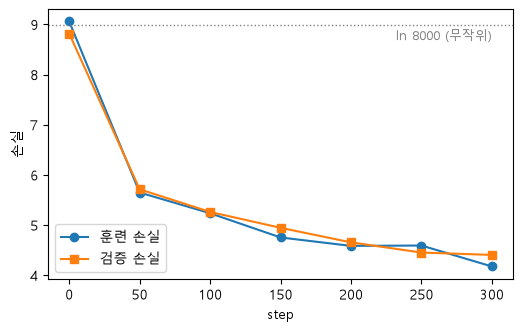

옛날 옛날에, 하고 대답했다.  원숭이는 더 이상 일을 보냈다.  나비는 풀을 부르고 웃었다.  동생은 기뻐하며 고맙다고 말했습니다.  하지만 친구들은 친구와 아이에게 물었다.



In [13]:
plt.figure(figsize=(6, 3.5))
plt.plot(history["step"], history["train"], "o-", label="훈련 손실")
plt.plot(history["step"], history["val"], "s-", label="검증 손실")
plt.axhline(math.log(8000), color="gray", ls=":", lw=1)
plt.text(STEPS, math.log(8000) - 0.3, "ln 8000 (무작위)", ha="right", color="gray", fontsize=9)
plt.xlabel("step")
plt.ylabel("손실")
plt.legend()
plt.show()

print(generate(model, "옛날 옛날에,", max_new=80))

손실이 9 근처에서 시작해 빠르게 내려갑니다. 몇 분 만에 글자와 짧은 말투는 흉내 내지만, 이야기는 아직 이어지지 않습니다.
실습 자료의 같은 크기 모델은 6억 토큰을 RTX 4090에서 약 15분 동안 훈련했습니다. 여기서 본 토큰 수(300 × 16 × 128 ≈ 61만)의 약 1,000배입니다.

## 훈련이 끝난 모델 불러오기

실습 자료의 `tiny_1ep.pt`를 불러옵니다. 체크포인트에는 가중치(`model`)와 설정(`config`), 훈련 스텝, 검증 손실이 들어 있습니다.

In [14]:
ck = torch.load(EXP02 / "checkpoints" / "tiny_1ep.pt", map_location="cpu", weights_only=False)
print(ck["config"])
print(f"훈련 스텝 {ck['iter']:,} · 검증 손실 {ck['val_loss']:.4f}")

trained = GPT(GPTConfig(**vars(ck["config"])))      # 저장된 설정으로 노트북의 GPT를 만들고
trained.load_state_dict(ck["model"])                 # 가중치를 그대로 넣습니다
trained.eval()
print("불러오기 완료")

GPTConfig(vocab_size=8000, d_model=256, n_layer=4, n_head=4, d_ff=704, max_seq_len=1024, rope_theta=10000.0, tie_embeddings=True)
훈련 스텝 34,500 · 검증 손실 1.8922
불러오기 완료


노트북에서 만든 클래스에 훈련된 가중치가 그대로 들어갑니다. 부품의 이름과 모양이 실습 자료의 모델과 같기 때문입니다.
체크포인트의 가중치는 용량을 줄이려고 bf16으로 저장돼 있고, 불러올 때 float32로 바뀝니다.

실습 자료의 생성 스크립트와 같은 프롬프트로 생성해 봅니다.

In [15]:
for i, prompt in enumerate(["옛날 옛날에,", "작은 다람쥐가 숲속에서", "어느 날, 토끼는", "엄마 곰은 아기 곰에게"]):
    print(generate(trained, prompt, max_new=150, seed=i))
    print()

옛날 옛날에, 아주 먼�으로 아름다운 섬이 펼쳐져 있습니다. 바람이 살랑살랑 불어 아이의 이름은 푸른 초원을 가득 달고 있습니다. 초원에는 아기 양들이 풀을 뜯어먹고 있습니다. 아이는 양들을 보며 행복해합니다. 갑자기 하늘에서 하늘에서 큰 독수리가 날아왔습니다. 독수리는 날카로운 눈으로 하늘을 내려다봅니다. 아이는 깜짝 놀라 소리칩니다. 독수리는 하늘에서 내려와 아이를 바라봅니다. 아이는 다시 소들에게 다가가 말합니다. "말에게 인사를 하지 말아야 한다." 아이는 소에게 달려가 말을 건넵니다. 소는 아이에게 기대고 아이를 풀밭에 내려줍니다. 아이는 소의 등에서 내려 아빠에게 달려가 도움을 요청합니다. 아빠는 아이를 걱정하며 집으로 데려갑니다. 아이는 아빠 손을 잡고 집으로 들어가 맛있게 사과를 먹습니다. 아이는 아빠의 말에 기분이 좋아집니다.



작은 다람쥐가 숲속에서 민들레를 찾았다.  다람쥐가 민들레를 따내려고 했다.  숲속에 큰 괴물이 나타났다.  괴물은 무서운 소리를 내며 울부짖었다.  다람쥐는 겁에 질려 도망치려 했다.  숲속에는 큰 호랑이가 나타났다.  호랑이는 으르렁거렸다.  큰 호랑이는 다람쥐에게 다가가 소리쳤다. 다람쥐는 겁에 질려 빨리 도망쳤다.  호랑이는 다람쥐를 잡으려고 했지만, 갑자기 개구리가 뛰어다녔다. 개구리는 호랑이의 손을 잡았다. 다람쥐는 개구리에게 고맙다고 말했다.  호랑이는 다람쥐에게 클로버를 주었다.  개구리는 맛있게 클로버를 먹었다.  다람쥐는 더 이상 무서워하지 않았다.



어느 날, 토끼는 밭에서 감자를 캐고 있었어요. 토끼는 맛있는 감자를 많이 캐서 친구들에게 자랑하고 싶었어요. 토끼는 친구에게 "내가 예쁜 감자를 주우러 가고 있어!"라고 말했어요. 토끼는 친구를 위해 감자를 캐고 있었는데, 친구들이 감자를 기다리고 있었어요. 토끼는 친구들과 함께 감자를 나눠 먹는 것이 더욱 즐거웠어요. 토끼는 앞으로도 친구들을 위해 착한 일을 하고 감자를 맛있게 먹을 거예요.



엄마 곰은 아기 곰에게  당근을 주지 않았다.  하지만 곰은 착하지 않았다.  엄마 곰은 아기 곰이 혼자 당근을 먹는 것이 싫었다.  다른 동물들은 아기 곰을 몰래 지켜보았다. 곰은 혼자서 다 먹고 싶었다.  결국, 엄마 곰은 아기 곰에게 다가왔다.  엄마 곰은 곰이 착해졌다는 소식을 들었다.  이제 곰은 당근을 친구들과 나누어 먹었다.  이제 아기 곰은 남의 것을 훔쳐 먹지 않았다.  착한 곰 덕분에 모두 행복했다.



몇 분 훈련한 모델과 달리 등장인물과 사건이 이야기 끝까지 이어집니다. 문장 사이가 어색하게 튀는 곳은 아직 남아 있습니다.
가끔 보이는 �는 모델이 한 글자를 이루는 바이트 조각을 잘못 이어 붙여 글자가 깨진 것입니다. 바이트에서 시작하는 BPE 모델에서 생기는 현상입니다.

## 어텐션 행렬 꺼내 보기

「트랜스포머의 구조」 강의에서 본 문장 「소녀가 예쁜 꽃을 보았어요. 그것은 정말 예뻤어요.」를 넣고, 각 층·헤드의 어텐션 가중치를 꺼냅니다.
BPE는 한 단어를 여러 토큰으로 나누기도 해서, 단어 단위로 묶어 봅니다. 보는 쪽(가로줄)은 그 단어의 마지막 토큰을 쓰고, 보이는 쪽(세로줄)은 단어에 속한 토큰들의 가중치를 더합니다.
층과 헤드 번호는 0부터 셉니다(실습 자료의 어텐션 뷰어와 같은 번호입니다).

In [16]:
sentence = "소녀가 예쁜 꽃을 보았어요. 그것은 정말 예뻤어요."
ids = tok.encode(sentence)
print("토큰:", [tok.vocab[i].decode("utf-8", errors="replace") for i in ids])

# 띄어쓰기로 시작하는 토큰과 마침표에서 단어를 나눕니다
groups = []
for i, t in enumerate(ids):
    piece = tok.vocab[t]
    if i == 0 or piece.startswith(b" ") or piece == b"." or tok.vocab[ids[i - 1]] == b".":
        groups.append([i])
    else:
        groups[-1].append(i)
labels = [tok.decode([ids[i] for i in g]).strip() for g in groups]
print("단어:", labels)

for blk in trained.blocks:
    blk.attn.keep_attn = True
with torch.no_grad():
    trained(torch.tensor([ids]))

def word_attention(att):                          # att: (T, T) 토큰 단위 → 단어 단위
    W = torch.zeros(len(groups), len(groups))
    for a, ga in enumerate(groups):
        for b, gb in enumerate(groups):
            W[a, b] = att[ga[-1], gb].sum()
    return W

src, dst = labels.index("그것은"), labels.index("꽃을")
print("\n층·헤드별 「그것은 → 꽃을」 가중치")
best = None
for l, blk in enumerate(trained.blocks):
    row = [word_attention(blk.attn.attn[0, h])[src, dst].item() for h in range(trained.cfg.n_head)]
    print(f"  층 {l}: " + "  ".join(f"헤드 {h} {v:.2f}" for h, v in enumerate(row)))
    for h, v in enumerate(row):
        if best is None or v > best[2]:
            best = (l, h, v)
print(f"가장 큰 곳: 층 {best[0]} 헤드 {best[1]} ({best[2]:.2f})")

토큰: ['소', '�', '�', '가', ' 예쁜', ' 꽃을', ' 보았어요', '.', ' 그것은', ' 정말', ' 예뻤어요', '.']
단어: ['소녀가', '예쁜', '꽃을', '보았어요', '.', '그것은', '정말', '예뻤어요', '.']

층·헤드별 「그것은 → 꽃을」 가중치
  층 0: 헤드 0 0.12  헤드 1 0.04  헤드 2 0.10  헤드 3 0.08
  층 1: 헤드 0 0.09  헤드 1 0.05  헤드 2 0.16  헤드 3 0.05
  층 2: 헤드 0 0.13  헤드 1 0.66  헤드 2 0.12  헤드 3 0.04
  층 3: 헤드 0 0.04  헤드 1 0.10  헤드 2 0.00  헤드 3 0.03
가장 큰 곳: 층 2 헤드 1 (0.66)


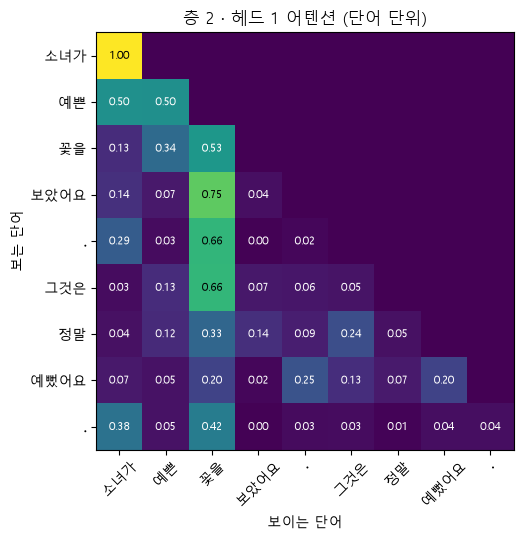

In [17]:
l, h, _ = best
W = word_attention(trained.blocks[l].attn.attn[0, h])
n = len(labels)

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.imshow(W, cmap="viridis", vmin=0, vmax=1)
ax.set_xticks(range(n), labels, rotation=45)
ax.set_yticks(range(n), labels)
ax.set_xlabel("보이는 단어")
ax.set_ylabel("보는 단어")
ax.set_title(f"층 {l} · 헤드 {h} 어텐션 (단어 단위)")
for i in range(n):
    for j in range(i + 1):
        ax.text(j, i, f"{W[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="k" if W[i, j] > 0.6 else "w")
plt.tight_layout()
plt.show()

「그것은」 줄에서 「꽃을」 칸이 가장 밝습니다. 대명사가 가리키는 대상을 어텐션이 찾아간 것입니다.
오른쪽 위가 비어 있는 것은 인과 마스크 때문입니다. 모델은 아직 나오지 않은 단어를 보지 못합니다.
다른 층과 헤드는 다른 곳을 봅니다. `l`, `h` 값을 바꿔 다시 그려 보세요.
실습 자료의 `attention_demo/attention_viewer.html`을 브라우저로 열면 층과 헤드를 눌러 가며 볼 수 있습니다.

## 정리

- RMSNorm, RoPE, 어텐션, SwiGLU를 부품으로 만들고, 블록으로 묶고, 블록을 쌓아 GPT를 조립했습니다.
- 훈련 루프는 학습률 → 순전파·손실 → 역전파 → 클리핑 → 업데이트 → 기울기 비우기의 반복입니다.
- 부품 이름과 모양이 같으면 다른 곳에서 훈련한 체크포인트를 노트북의 모델에 그대로 넣을 수 있습니다.
- 훈련된 모델의 어텐션을 꺼내 보면, 대명사가 앞의 명사를 찾아가는 헤드가 있습니다.